# add_messages 리듀서

**이 노트북에서 할 일**

1. 사람 역할 메시지와 모델 역할 메시지를 손으로 하나씩 만들어 봅니다.
2. 메시지 리듀서를 그래프 없이 불러 새 번호와 같은 번호를 견줍니다.
3. 02절 함수 `operator.add`로 똑같은 일을 해 보고 남는 메시지 수를 견줍니다.
4. 메시지 칸을 둔 그래프를 실행하고 그 결과를 다시 넣어 한 번 더 실행합니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청이 0번이라 드는 비용이 없습니다.
이 절의 모델 역할 메시지는 우리가 손으로 만든 것이고 모델이 쓴 답이 아닙니다.
읽어 오는 자료 파일도 없고 새로 쓰는 파일도 없습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11과 LangChain 1.4.0을 설치합니다.
메시지 클래스가 LangChain 쪽에 있어 01~03절보다 패키지가 하나 늘었습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
메시지를 손으로 만들고 리듀서를 그래프 없이 불러 본 뒤 그래프에 붙이는 자리입니다.
8절과 9절은 값을 하나씩 바꿔 보는 자리입니다.
10절은 여섯 목록을 기록 한 줄씩으로 만들어 표로 견주는 자리입니다.
준비부터 끝까지 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

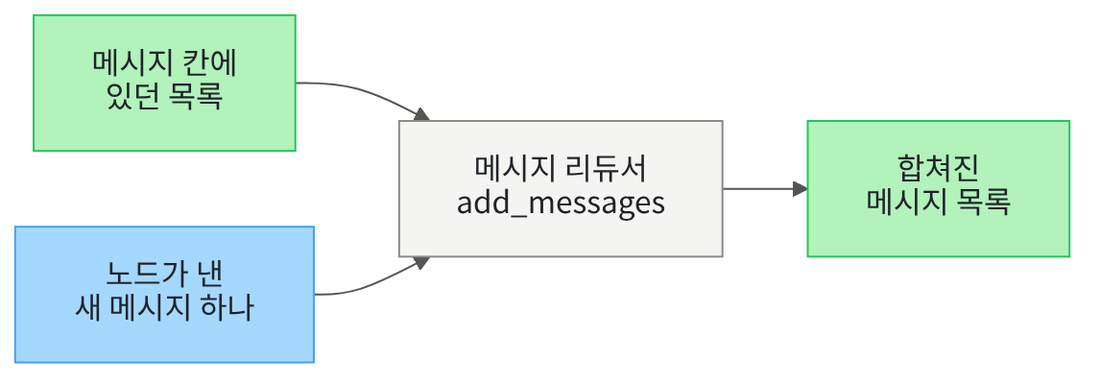

왼쪽 위 초록 상자가 메시지 칸에 이미 있던 목록입니다.
왼쪽 아래 파란 상자가 노드 하나가 낸 새 메시지입니다.
가운데 회색 상자가 라이브러리가 주는 메시지 리듀서입니다.
오른쪽 초록 상자가 리듀서를 지난 뒤 칸에 남는 목록입니다.

## 1. 준비

첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 설치가 끝나면 `langgraph: 1.2.11`과 `langchain: 1.4.0`이 보입니다.
이 노트북의 출력은 2026-09-19에 이 두 판으로 실행한 결과입니다.

다음 셀은 이름 아홉 개를 불러옵니다.
앞의 다섯은 02절에서 불러온 것과 같습니다.
뒤의 넷이 이 절에서 처음 쓰는 메시지 이름입니다.

In [2]:
# 02절 이름 다섯 개에 메시지 이름 넷을 더해 불러옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AnyMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

print("메시지 이름 넷:", "AnyMessage", "HumanMessage", "AIMessage", "add_messages")

메시지 이름 넷: AnyMessage HumanMessage AIMessage add_messages


**결과 읽기** — 출력 줄 `메시지 이름 넷: AnyMessage HumanMessage AIMessage add_messages`가 보입니다.
앞의 셋은 메시지 클래스이고 Ch 6 02절에서 이미 만들어 본 이름입니다.
마지막 `add_messages`가 이 절에서 처음 쓰는 리듀서입니다.

## 2. 이 절에서 쓸 값 정하기

01절부터 쓴 첫 질문을 글자까지 같게 씁니다.
메시지마다 붙일 번호 두 개와 모델 역할 자리에 적어 둘 글도 함께 정합니다.

In [3]:
# 01절 질문과 이 절 메시지에 붙일 번호 두 개와 적어 둘 글을 정합니다
first_question = "  대출 기간은 며칠인가요?  "
question_id = "h1"
answer_id = "a1"
answer_text = "찾은 자료로 답을 만듭니다"
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("사람 역할 메시지의 번호:", question_id)
print("모델 역할 메시지의 번호:", answer_id)
print("모델 역할 자리에 적어 둘 글:", answer_text)

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
사람 역할 메시지의 번호: h1
모델 역할 메시지의 번호: a1
모델 역할 자리에 적어 둘 글: 찾은 자료로 답을 만듭니다


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`은 01절부터 이어지는 같은 값입니다.
출력 줄 `사람 역할 메시지의 번호: h1`과 `모델 역할 메시지의 번호: a1`이 이 절에서 쓸 번호입니다.
번호는 라이브러리가 정해 준 값이 아니라 우리가 지은 이름표입니다.
출력 줄의 글 `찾은 자료로 답을 만듭니다`는 03절 답 칸에 적었던 글과 같습니다.

## 3. 메시지 객체 만들기

메시지 객체는 역할을 클래스 이름으로 드러낸 메시지입니다.
Ch 6 02절에서 튜플 대신 메시지 객체로 질문을 보내 본 적이 있습니다.
여기서는 그때와 같은 클래스에 번호를 하나 더 붙입니다.

In [4]:
# 앞뒤 빈칸을 없앤 질문으로 사람 역할 메시지 하나를 만듭니다
clean_question = first_question.strip()
question_message = HumanMessage(content=clean_question, id=question_id)
print("역할 이름:", question_message.type)
print("메시지 번호:", question_message.id)
print("메시지의 글:", question_message.text)

역할 이름: human
메시지 번호: h1
메시지의 글: 대출 기간은 며칠인가요?


**결과 읽기** — 출력 줄 `역할 이름: human`이 이 메시지의 역할입니다.
출력 줄 `메시지 번호: h1`이 우리가 붙인 번호입니다.
출력 줄 `메시지의 글: 대출 기간은 며칠인가요?`에는 앞뒤 빈칸이 없습니다.
속성 `text`는 메시지 안의 글만 꺼내 줍니다.

다음 셀은 모델 역할 메시지를 손으로 만듭니다.
모델을 부르지 않으므로 이 메시지의 글은 모델이 쓴 답이 아닙니다.

In [5]:
# 모델을 부르지 않고 모델 역할 메시지 하나를 손으로 만듭니다
answer_message = AIMessage(content=answer_text, id=answer_id)
print("역할 이름:", answer_message.type)
print("메시지 번호:", answer_message.id)
print("메시지의 글:", answer_message.text)

역할 이름: ai
메시지 번호: a1
메시지의 글: 찾은 자료로 답을 만듭니다


**결과 읽기** — 출력 줄 `역할 이름: ai`가 앞 메시지와 다른 자리입니다.
출력 줄 `메시지 번호: a1`이 이 메시지의 번호입니다.
출력 줄 `메시지의 글: 찾은 자료로 답을 만듭니다`는 우리가 적어 둔 글입니다.
모델이 만든 문장이 아니라 자리를 채우려고 적은 글입니다.

다음 셀은 메시지 목록을 한 줄씩 출력하는 함수입니다.
01절부터 쓴 `print_state`처럼 라벨 줄을 따로 두고 그 아래에 한 줄씩 적습니다.

In [6]:
# 메시지 목록을 라벨 줄 아래에 한 줄씩 출력합니다
def print_messages(label, messages):
    print(label)
    for message in messages:
        print(message.type, "|", message.id, "|", message.text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
한 줄에 역할 이름과 번호와 글을 막대 기호로 나눠 적습니다.
메시지가 여러 개면 줄도 여러 개가 나옵니다.

다음 셀은 앞에서 만든 메시지 두 개를 한 목록에 담습니다.

In [7]:
# 앞에서 만든 메시지 두 개를 한 목록에 담아 출력합니다
first_list = [question_message, answer_message]
print_messages("손으로 담은 메시지 목록", first_list)
print("메시지 수:", len(first_list))

손으로 담은 메시지 목록
human | h1 | 대출 기간은 며칠인가요?
ai | a1 | 찾은 자료로 답을 만듭니다
메시지 수: 2


**결과 읽기** — 라벨 줄 `손으로 담은 메시지 목록` 아래 두 줄이 나옵니다.
첫 줄은 `human | h1 |`로 시작하고 둘째 줄은 `ai | a1 |`로 시작합니다.
출력 줄 `메시지 수: 2`가 담은 개수입니다.
여기까지는 리듀서를 한 번도 부르지 않고 목록에 손으로 담기만 했습니다.

## 4. 메시지 리듀서를 그래프 없이 불러 보기

메시지 리듀서 `add_messages`는 목록 두 개를 받아 하나로 합치는 함수입니다.
02절 `operator.add`와 자리는 같지만 합치는 방법이 다릅니다.
먼저 그래프 없이 직접 불러 봅니다.
바뀌는 값은 넣는 메시지의 번호 하나뿐입니다.

In [8]:
# 번호가 새로운 메시지 하나를 메시지 리듀서로 더해 봅니다
more_message = HumanMessage(content="반납은 어디서 하나요", id="h2")
added = add_messages(first_list, [more_message])
print_messages("새 번호를 더한 뒤", added)
print("메시지 수:", len(added))

새 번호를 더한 뒤
human | h1 | 대출 기간은 며칠인가요?
ai | a1 | 찾은 자료로 답을 만듭니다
human | h2 | 반납은 어디서 하나요
메시지 수: 3


**결과 읽기** — 라벨 줄 `새 번호를 더한 뒤` 아래 세 줄이 나옵니다.
셋째 줄이 `human | h2 |`로 시작하는 새 메시지입니다.
출력 줄 `메시지 수: 3`으로 하나 늘었습니다.
번호가 목록에 없던 값이라 뒤에 붙었습니다.

다음 셀은 이미 목록에 있는 번호 `h1`을 다시 넣습니다.
실행 전에 예상해 봅니다. 번호가 같으니 개수는 셋 그대로일 것입니다.

In [9]:
# 번호가 같은 메시지를 넣어 같은 목록에 다시 더해 봅니다
fixed_question = HumanMessage(content="도서 대출 기간은 며칠", id=question_id)
replaced = add_messages(added, [fixed_question])
print_messages("같은 번호를 넣은 뒤", replaced)
print("메시지 수:", len(replaced))

같은 번호를 넣은 뒤
human | h1 | 도서 대출 기간은 며칠
ai | a1 | 찾은 자료로 답을 만듭니다
human | h2 | 반납은 어디서 하나요
메시지 수: 3


**결과 읽기** — 라벨 줄 `같은 번호를 넣은 뒤` 아래 세 줄이 나옵니다.
첫 줄의 글이 `도서 대출 기간은 며칠`로 바뀌었습니다.
출력 줄 `메시지 수: 3`은 앞 셀과 같습니다.
새 메시지가 뒤에 붙지 않고 첫 자리 메시지의 글만 바뀌었습니다.
이렇게 같은 자리에서 글이 바뀌는 일을 이 절에서는 바꿔 넣기라고 부릅니다.

## 5. 02절 함수와 견주기

같은 목록에 같은 메시지를 02절 함수 `operator.add`로 넣어 봅니다.
실행 전에 예상해 봅니다. 번호를 보지 않으므로 뒤에 그냥 붙을 것입니다.

In [10]:
# 02절에서 쓴 operator.add로 똑같은 일을 해 봅니다
plain = operator.add(added, [fixed_question])
print_messages("operator.add로 이어 붙인 뒤", plain)
print("메시지 수:", len(plain))

operator.add로 이어 붙인 뒤
human | h1 | 대출 기간은 며칠인가요?
ai | a1 | 찾은 자료로 답을 만듭니다
human | h2 | 반납은 어디서 하나요
human | h1 | 도서 대출 기간은 며칠
메시지 수: 4


**결과 읽기** — 라벨 줄 `operator.add로 이어 붙인 뒤` 아래 네 줄이 나옵니다.
첫 줄과 넷째 줄의 번호가 모두 `h1`입니다.
출력 줄 `메시지 수: 4`로 하나 늘었습니다.
첫 줄의 글은 바뀌지 않고 그대로입니다.

다음 셀은 두 함수가 만든 목록을 나란히 견줍니다.

In [11]:
# 두 함수가 만든 목록을 견줍니다
print("메시지 리듀서가 만든 수:", len(replaced))
print("operator.add가 만든 수:", len(plain))
print("첫 메시지의 글이 같은가:", replaced[0].text == plain[0].text)
print("리듀서 판 첫 메시지의 글:", replaced[0].text)
print("이어 붙인 판 첫 메시지의 글:", plain[0].text)
assert len(replaced) == 3
assert len(plain) == 4

메시지 리듀서가 만든 수: 3
operator.add가 만든 수: 4
첫 메시지의 글이 같은가: False
리듀서 판 첫 메시지의 글: 도서 대출 기간은 며칠
이어 붙인 판 첫 메시지의 글: 대출 기간은 며칠인가요?


**결과 읽기** — 출력 줄 `메시지 리듀서가 만든 수: 3`과 `operator.add가 만든 수: 4`가 갈린 자리입니다.
출력 줄 `첫 메시지의 글이 같은가: False`도 함께 갈렸습니다.
리듀서 판 첫 메시지의 글은 `도서 대출 기간은 며칠`이고 이어 붙인 판은 `대출 기간은 며칠인가요?`입니다.
같은 목록에 같은 메시지를 넣었는데 남는 값이 달라졌습니다.
칸에 어느 리듀서를 적었는지가 이 차이를 만듭니다.

## 6. 상태 형식과 노드

이제 메시지 칸을 둔 상태 형식을 만듭니다.
칸은 질문 칸과 메시지 칸과 실행 흔적 칸 셋입니다.
메시지 칸에는 메시지 리듀서를 적고 실행 흔적 칸에는 02절 규칙을 그대로 적습니다.

In [12]:
# 메시지 칸에 메시지 리듀서를 적은 상태 형식을 만듭니다
class ChatState(TypedDict):
    question: str
    messages: Annotated[list[AnyMessage], add_messages]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
형식 이름 `AnyMessage`는 역할이 다른 메시지를 한 목록에 담을 때 쓰는 공통 형식입니다.
표시 `Annotated`의 둘째 자리에 적은 함수가 그 칸의 규칙입니다.
메시지 칸과 실행 흔적 칸에 서로 다른 규칙을 적었습니다.

다음 셀은 01절부터 쓴 출력 함수를 이 절 칸에 맞춘 판입니다.

In [13]:
# 상태의 칸 세 개를 라벨 줄 아래에 한 줄씩 출력합니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("메시지 칸의 메시지 수 |", len(state["messages"]))
    print("실행 흔적 칸 |", state["trace"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지 칸은 줄이 여러 개라 여기서는 개수만 적고 내용은 `print_messages`로 따로 봅니다.
03절 판과 견주면 점수 칸과 답 칸 줄이 빠지고 메시지 칸 줄이 들어왔습니다.

다음 셀은 01절부터 쓴 노드입니다. 하는 일은 02절과 같고 변수 이름만 `clean`으로 적었습니다.

In [14]:
# 질문 칸의 앞뒤 빈칸을 없애고 실행 흔적에는 자기 이름만 담아 냅니다
def normalize(state):
    clean = state["question"].strip()
    return {"question": clean, "trace": ["normalize"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `strip()`은 글 앞뒤의 빈칸을 없앱니다.
이 노드는 메시지 칸을 건드리지 않습니다.

다음 셀은 질문 칸의 글로 사람 역할 메시지를 만드는 노드입니다.

In [15]:
# 질문 칸의 글로 사람 역할 메시지 하나만 담아 냅니다
def write_question(state):
    message = HumanMessage(content=state["question"], id=question_id)
    return {"messages": [message], "trace": ["write_question"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 메시지 목록 전체가 아니라 새 메시지 하나만 담아 냅니다.
목록을 합치는 일은 칸에 적은 리듀서가 합니다.
02절이 정한 약속과 같은 모양입니다.

다음 셀은 모델 역할 메시지를 만드는 노드입니다.

In [16]:
# 모델을 부르지 않고 모델 역할 메시지 하나만 담아 냅니다
def write_answer(state):
    message = AIMessage(content=answer_text, id=answer_id)
    return {"messages": [message], "trace": ["write_answer"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드도 모델을 부르지 않고 앞에서 정한 글을 그대로 담습니다.
그래서 이 메시지의 글은 모델이 쓴 답이 아닙니다.

## 7. 조립과 1회 실행

설계 객체를 만들고 노드 세 개를 등록합니다.
갈래가 없으므로 03절과 달리 조건부 엣지는 쓰지 않습니다.

In [17]:
# 설계 객체를 만들고 노드 세 개를 등록합니다
builder = StateGraph(ChatState)
builder.add_node("normalize", normalize)
builder.add_node("write_question", write_question)
builder.add_node("write_answer", write_answer)
print("등록한 노드 수:", len(builder.nodes))

등록한 노드 수: 3


**결과 읽기** — 출력 줄 `등록한 노드 수: 3`이 보입니다.
03절은 넷이었고 01절·02절은 둘이었습니다.

다음 셀은 고정 엣지 네 개를 적고 컴파일합니다.

In [18]:
# 고정 엣지 네 개로 한 갈래 길을 적고 컴파일합니다
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "write_question")
builder.add_edge("write_question", "write_answer")
builder.add_edge("write_answer", END)
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph))

고정 엣지로 적은 수: 4
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 4`가 보입니다.
이 그래프에는 조건부 엣지가 하나도 없습니다.
출력 줄의 종류 이름 `CompiledStateGraph`는 01절부터 같습니다.

다음 셀은 메시지 칸을 빈 목록으로 두고 실행합니다.
실행 전에 예상해 봅니다. 노드 둘이 메시지를 하나씩 내니 메시지 칸에는 둘이 남을 것입니다.

In [19]:
# 메시지 칸을 빈 목록으로 두고 그래프를 실행합니다
start_state = {"question": first_question, "messages": [], "trace": []}
first_result = graph.invoke(start_state)
print_state("1회 실행 결과", first_result)

1회 실행 결과
질문 칸 | 대출 기간은 며칠인가요?
메시지 칸의 메시지 수 | 2
실행 흔적 칸 | ['normalize', 'write_question', 'write_answer']


**결과 읽기** — 줄 `메시지 칸의 메시지 수 | 2`가 남은 개수입니다.
줄 `실행 흔적 칸 | ['normalize', 'write_question', 'write_answer']`에 이름 셋이 남았습니다.
줄 `질문 칸 | 대출 기간은 며칠인가요?`는 01절부터 같은 값입니다.

다음 셀은 그 메시지 칸을 한 줄씩 펼쳐 봅니다.

In [20]:
# 1회 실행 결과의 메시지 칸을 한 줄씩 출력합니다
print_messages("1회 실행 결과의 메시지 칸", first_result["messages"])
print("메시지 수:", len(first_result["messages"]))

1회 실행 결과의 메시지 칸
human | h1 | 대출 기간은 며칠인가요?
ai | a1 | 찾은 자료로 답을 만듭니다
메시지 수: 2


**결과 읽기** — 라벨 줄 `1회 실행 결과의 메시지 칸` 아래 두 줄이 나옵니다.
첫 줄은 `human | h1 | 대출 기간은 며칠인가요?`입니다.
둘째 줄은 `ai | a1 | 찾은 자료로 답을 만듭니다`입니다.
노드는 메시지를 하나씩만 냈는데 칸에는 둘이 모였습니다.

다음 셀은 목록의 마지막 자리에서 글만 꺼냅니다.
자리 번호 `-1`은 목록의 마지막 자리를 뜻합니다.

In [21]:
# 메시지 칸의 마지막 메시지에서 글만 읽어 봅니다
last_message = first_result["messages"][-1]
print("마지막 메시지의 역할 이름:", last_message.type)
print("마지막 메시지의 번호:", last_message.id)
print("마지막 메시지의 글:", last_message.text)

마지막 메시지의 역할 이름: ai
마지막 메시지의 번호: a1
마지막 메시지의 글: 찾은 자료로 답을 만듭니다


**결과 읽기** — 출력 줄 `마지막 메시지의 역할 이름: ai`가 보입니다.
출력 줄 `마지막 메시지의 번호: a1`이 그 메시지의 번호입니다.
출력 줄 `마지막 메시지의 글: 찾은 자료로 답을 만듭니다`가 속성 `text`로 꺼낸 값입니다.
이 글은 노드 `write_answer`가 적어 둔 것이고 모델이 쓴 답이 아닙니다.

## 8. 값 바꿔 보기 ① 결과를 다시 넣기

바꿀 값은 그래프에 넣는 처음 상태 하나입니다.
1회 실행 결과를 그대로 다시 넣습니다.
실행 전에 예상해 봅니다.
번호 `h1`과 `a1`이 이미 있으니 메시지 수는 둘 그대로일 것입니다.

In [22]:
# 1회 실행 결과를 그대로 다시 넣어 같은 그래프를 실행합니다
second_result = graph.invoke(first_result)
print_state("2회 실행 결과", second_result)
print("실행 흔적 칸의 길이:", len(second_result["trace"]))

2회 실행 결과
질문 칸 | 대출 기간은 며칠인가요?
메시지 칸의 메시지 수 | 2
실행 흔적 칸 | ['normalize', 'write_question', 'write_answer', 'normalize', 'write_question', 'write_answer']
실행 흔적 칸의 길이: 6


**결과 읽기** — 줄 `메시지 칸의 메시지 수 | 2`가 1회 실행과 같습니다.
출력 줄 `실행 흔적 칸의 길이: 6`은 셋에서 여섯으로 늘었습니다.
한 상태 안에서 메시지 칸은 그대로고 실행 흔적 칸만 늘었습니다.
칸마다 적은 리듀서가 달라서 생긴 차이입니다.

다음 셀은 2회 실행 결과의 메시지 칸을 펼쳐 봅니다.

In [23]:
# 2회 실행 결과의 메시지 칸을 한 줄씩 출력합니다
print_messages("2회 실행 결과의 메시지 칸", second_result["messages"])
assert len(second_result["messages"]) == 2

2회 실행 결과의 메시지 칸
human | h1 | 대출 기간은 며칠인가요?
ai | a1 | 찾은 자료로 답을 만듭니다


**결과 읽기** — 라벨 줄 `2회 실행 결과의 메시지 칸` 아래 두 줄이 나옵니다.
번호도 글도 1회 실행과 같습니다.
같은 번호 메시지가 같은 자리에서 다시 쓰였습니다.

## 9. 값 바꿔 보기 ② 번호를 붙이지 않으면

바꿀 값은 넣는 메시지의 번호 하나입니다.
이번에는 번호를 아예 적지 않고 만듭니다.
실행 전에 예상해 봅니다.
바꿔 넣을 자리를 찾을 수 없으니 뒤에 붙을 것입니다.

In [24]:
# 번호를 적지 않은 메시지를 1회 실행 결과에 더해 봅니다
no_id_message = HumanMessage(content="연체하면 어떻게 되나요")
grown = add_messages(first_result["messages"], [no_id_message])
print("메시지 수:", len(grown))
print("자동으로 붙은 번호의 글자 수:", len(grown[-1].id))
print("앞 메시지와 번호가 같은가:", grown[0].id == grown[-1].id)

메시지 수: 3
자동으로 붙은 번호의 글자 수: 36
앞 메시지와 번호가 같은가: False


**결과 읽기** — 출력 줄 `메시지 수: 3`으로 하나 늘었습니다.
출력 줄 `자동으로 붙은 번호의 글자 수: 36`이 라이브러리가 붙인 번호의 길이입니다.
그 번호는 실행할 때마다 달라지므로 값 자체는 인용하지 않습니다.
출력 줄 `앞 메시지와 번호가 같은가: False`라서 바꿔 넣기가 일어나지 않았습니다.

## 10. 여섯 목록을 기록 한 줄씩으로

목록 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12와 01~03절에서 쓴 기록 한 줄과 같은 모양입니다.

In [25]:
# 목록 하나를 기록 한 줄로 만듭니다
def run_row(list_name, messages):
    row = {"목록": list_name}
    row["메시지 수"] = len(messages)
    row["첫 메시지의 글"] = messages[0].text
    row["마지막 메시지의 역할"] = messages[-1].type
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
03절 판과 견주면 담는 칸이 메시지 수와 첫 메시지의 글과 마지막 역할로 바뀌었습니다.
이 절이 견주는 값이 목록의 길이와 첫 자리 글이기 때문입니다.

다음 셀은 여섯 목록의 기록을 한 목록에 담습니다.

In [26]:
# 여섯 목록의 기록을 한 목록에 담습니다
run_rows = []
run_rows.append(run_row("새 번호를 더한 뒤", added))
run_rows.append(run_row("같은 번호를 넣은 뒤", replaced))
run_rows.append(run_row("operator.add로 이어 붙인 뒤", plain))
run_rows.append(run_row("그래프 1회 실행", first_result["messages"]))
run_rows.append(run_row("그래프 2회 실행", second_result["messages"]))
run_rows.append(run_row("번호 없는 메시지를 더한 뒤", grown))
print("담은 기록 줄 수:", len(run_rows))

담은 기록 줄 수: 6


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 6`이 보입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [27]:
# 목록과 메시지 수와 첫 메시지의 글과 마지막 역할을 라벨 줄 아래에 출력합니다
print("목록 | 메시지 수 | 첫 메시지의 글 | 마지막 메시지의 역할")
for row in run_rows:
    print(row["목록"], "|", row["메시지 수"], "|", row["첫 메시지의 글"], "|", row["마지막 메시지의 역할"])

목록 | 메시지 수 | 첫 메시지의 글 | 마지막 메시지의 역할
새 번호를 더한 뒤 | 3 | 대출 기간은 며칠인가요? | human
같은 번호를 넣은 뒤 | 3 | 도서 대출 기간은 며칠 | human
operator.add로 이어 붙인 뒤 | 4 | 대출 기간은 며칠인가요? | human
그래프 1회 실행 | 2 | 대출 기간은 며칠인가요? | ai
그래프 2회 실행 | 2 | 대출 기간은 며칠인가요? | ai
번호 없는 메시지를 더한 뒤 | 3 | 대출 기간은 며칠인가요? | human


**결과 읽기** — 라벨 줄 아래 여섯 줄이 나옵니다.
첫 줄과 둘째 줄은 메시지 수가 같고 첫 메시지의 글만 다릅니다.
셋째 줄만 메시지 수가 넷이고 그 줄이 `operator.add`로 이어 붙인 결과입니다.
넷째 줄과 다섯째 줄은 메시지 수도 첫 글도 같습니다.
여섯째 줄은 번호를 붙이지 않아 메시지 수가 셋입니다.

## 정리

1. 메시지 칸에 메시지 리듀서를 적으니 노드가 낸 메시지 하나가 목록 뒤에 붙었습니다.
2. 같은 번호 메시지는 자리에서 글만 바뀌었고 `operator.add`는 번호를 보지 않아 개수가 늘었습니다.
3. 1회 결과를 다시 넣어 실행해도 메시지 수는 둘 그대로였고 실행 흔적만 여섯으로 늘었습니다.

05절에서는 입력 수만큼 같은 노드를 여러 번 실행하는 `Send`를 씁니다.
이 절까지 그래프는 노드를 한 번씩만 지났습니다.